# ECL integrada: 18 configuraciones comparables
## Resumen
Tres PD × tres LGD × dos adaptadores de EAD producen 18 configuraciones con la misma cartera, escenarios y stages. La ECL agregada va de 69.345,73 a 148.061,92 unidades bajo estas especificaciones y supuestos. Se reconcilian contribuciones mensuales y agregaciones. Las diferencias son riesgo de especificación dentro de este laboratorio, no intervalos de confianza ni opciones para escoger la provisión menor.

## Contexto y métodos
$ECL_s=\sum_m q_{m,s}LGD_{m,s}EAD_{m,s}(1+EIR)^{-m/12}$; $ECL=\sum_s w_sECL_s$. Stage 1 selecciona eventos de default de meses 1–12 y Stage 2 todos los meses de vida contractual. LGD incluye recuperaciones posteriores al evento. Stage 3 aplica saldo financiado menos PV de recuperaciones netas.

### Supuestos
Stages fijos para comparar componentes. PD origen/actual de la política son entradas sintéticas sobre horizontes comparables; no se reconstruyen con cada challenger. No se implementan POCI, modificaciones, intereses netos ni asientos. El factor macro es estandarizado, con coeficientes prospectivos supuestos o estimados según modelo. [IFRS Foundation: escenarios y no linealidad](https://www.ifrs.org/news-and-events/news/2016/07/25-webcast-on-ifrs-9/).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.multimodel import *
from src.multimodel.experiment import fit_experiment
from src.multimodel.validation import binary_metrics, bootstrap_mean_interval
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#245B78", "#BE672F", "#398168"]
ex = fit_experiment()


## Datos: cartera al corte y configuración

In [2]:
print("Contratos:",len(ex["loans"]),"Saldo:",round(ex["loans"].balance.sum(),2))
display(ex["loans"].groupby(["product","stage"]).agg(contratos=("loan_id","size"),saldo=("balance","sum")).round(2))
display(ex["comparison"][["pd","lgd","ead","ecl","coverage"]].round(5))

Contratos: 180 Saldo: 1771732.51


contratos      saldo
product  stage                      
revolver 1             20  187690.65
         2             19  165441.09
         3              1    5805.40
term     1             77  864529.86
         2             59  522301.84
         3              4   25963.66

,pd,lgd,ead,ecl,coverage
0,pd_logit_12m,lgd_segment_workout,ead_contractual_fixed_ccf,71185.65236,0.04018
1,pd_logit_12m,lgd_segment_workout,ead_prepayment_fitted_ccf,69345.73374,0.03914
2,pd_logit_12m,lgd_fractional_workout,ead_contractual_fixed_ccf,75376.46795,0.04254
3,pd_logit_12m,lgd_fractional_workout,ead_prepayment_fitted_ccf,73450.59787,0.04146
4,pd_logit_12m,lgd_recovery_cashflows,ead_contractual_fixed_ccf,104286.37752,0.05886
5,pd_logit_12m,lgd_recovery_cashflows,ead_prepayment_fitted_ccf,101343.28975,0.05720
6,pd_monthly_survival,lgd_segment_workout,ead_contractual_fixed_ccf,77742.74187,0.04388
7,pd_monthly_survival,lgd_segment_workout,ead_prepayment_fitted_ccf,75594.86624,0.04267
8,pd_monthly_survival,lgd_fractional_workout,ead_contractual_fixed_ccf,82128.55715,0.04635
9,pd_monthly_survival,lgd_fractional_workout,ead_prepayment_fitted_ccf,79888.57052,0.04509


## Resultados: combinaciones y efecto de exposición

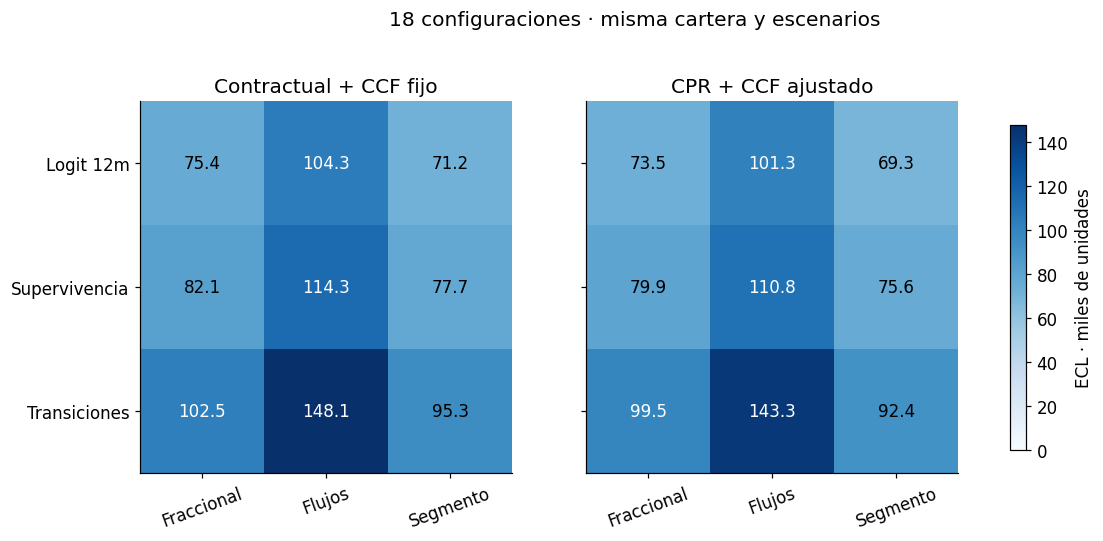

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,ead in zip(axes,ex["comparison"].ead.unique()):
    table=ex["comparison"].query("ead == @ead").pivot(index="pd",columns="lgd",values="ecl")
    image=ax.imshow(table.to_numpy()/1000,cmap="Blues",vmin=0,vmax=ex["comparison"].ecl.max()/1000)
    ax.set_xticks(range(3),["Fraccional","Flujos","Segmento"],rotation=20)
    ax.set_yticks(range(3),["Logit 12m","Supervivencia","Transiciones"])
    ax.set_title("Contractual + CCF fijo" if "contractual" in ead else "CPR + CCF ajustado")
    for i in range(3):
        for j in range(3):ax.text(j,i,f"{table.iloc[i,j]/1000:.1f}",ha="center",va="center",color="black" if table.iloc[i,j]<ex["comparison"].ecl.max()*.65 else "white")
fig.colorbar(image,ax=axes.ravel().tolist(),label="ECL · miles de unidades",shrink=.8)
fig.suptitle("18 configuraciones · misma cartera y escenarios",y=1.02);plt.show()

### Trazabilidad y reconciliación
Cada resultado conserva modelos, escenario, mes, PD marginal, LGD, EAD, contribución y selección por horizonte.

In [4]:
run=run_ecl(ex["loans"],ex["pd_models"][1],ex["lgd_models"][1],ex["ead_models"][1],ex["scenarios"])
np.testing.assert_allclose(run["loans"].ecl.sum(),run["scenarios"].weighted_ecl.sum())
monthly=run["monthly"].query("selected").groupby(["loan_id","scenario"]).contribution.sum()
live=run["scenarios"].query("stage != 3").set_index(["loan_id","scenario"]).ecl
np.testing.assert_allclose(monthly.reindex(live.index),live)
print("Modelos:",run["models"])
display(run["monthly"].head(6).round(6))
display(run["scenarios"].groupby("scenario").agg(ecl=("ecl","sum"),ponderada=("weighted_ecl","sum")).round(2))

Modelos: {'pd': 'pd_monthly_survival', 'lgd': 'lgd_fractional_workout', 'ead': 'ead_prepayment_fitted_ccf'}


,loan_id,scenario,month,marginal_pd,lgd,ead,contribution,selected
0,100000,base,1,0.007643,0.347518,15908.959228,41.725321,True
1,100000,base,2,0.007733,0.347518,14512.906112,38.031572,True
2,100000,base,3,0.007803,0.347518,13130.099261,34.284259,True
3,100000,base,4,0.007857,0.347518,11760.396366,30.532695,True
4,100000,base,5,0.007898,0.347518,10403.656623,26.811025,True
5,100000,base,6,0.007928,0.347518,9059.740717,23.143550,True


,ecl,ponderada
scenario,,
adverse,112205.03,33661.51
base,68190.78,40914.47
upside,53125.92,5312.59


### No linealidad de los escenarios
Se compara ponderar ECL de cada escenario con evaluar el factor macro promedio. Para aislar macro se mantienen iguales las recuperaciones Stage 3; la diferencia no mezcla haircuts adicionales.

In [5]:
scenario_macro=[Scenario(s.name,s.weight,s.macro) for s in ex["scenarios"]]
mean_path=sum(s.weight*np.array(s.macro) for s in scenario_macro)
a=run_ecl(ex["loans"],ex["pd_models"][1],ex["lgd_models"][1],ex["ead_models"][1],scenario_macro)["loans"].ecl.sum()
b=run_ecl(ex["loans"],ex["pd_models"][1],ex["lgd_models"][1],ex["ead_models"][1],[Scenario("mean_macro",1.,tuple(mean_path))])["loans"].ecl.sum()
print(f"Promedio ECL: {a:,.2f}; ECL macro promedio: {b:,.2f}; diferencia: {a-b:,.2f}")

Promedio ECL: 79,210.68; ECL macro promedio: 76,366.06; diferencia: 2,844.62


### Sensibilidad de política SICR
La condición cuantitativa exige umbral relativo y absoluto; mora e indicadores cualitativos operan como respaldo. Estas cifras son decisiones de laboratorio, no umbrales universales IFRS 9.

In [6]:
sensitivity=[]
for threshold in [1.5,2.,2.5,3.]:
    p=ex["loans"].drop(columns=["stage","stage_reason"]).copy()
    p=p.join(classify(p,ratio_threshold=threshold))
    r=run_ecl(p,ex["pd_models"][1],ex["lgd_models"][1],ex["ead_models"][1],ex["scenarios"])
    sensitivity.append({"umbral_relativo":threshold,"Stage_2":int((p.stage==2).sum()),"ECL":r["loans"].ecl.sum()})
display(pd.DataFrame(sensitivity).round(2))

,umbral_relativo,Stage_2,ECL
0,1.5,113,85350.58
1,2.0,78,79888.57
2,2.5,49,78107.53
3,3.0,17,76169.81


### Stage 3: monto y tiempo, sin PD futura

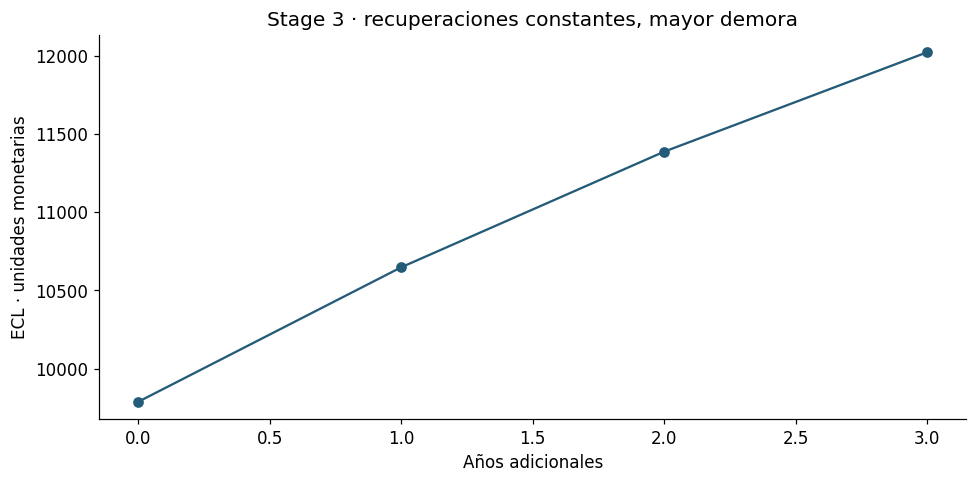

In [7]:
p=ex["loans"].iloc[[0]].copy();p["stage"]=3
rows=[]
for delay in [0,1,2,3]:
    s=[Scenario("recovery",1.,tuple(np.zeros(36)),1.,delay)]
    r=run_ecl(p,ex["pd_models"][0],ex["lgd_models"][0],ex["ead_models"][0],s)
    rows.append({"demora_años":delay,"ECL":r["loans"].ecl.sum()})
fig,ax=plt.subplots();ax.plot([r["demora_años"] for r in rows],[r["ECL"] for r in rows],"o-",color=COLORS[0])
ax.set(title="Stage 3 · recuperaciones constantes, mayor demora",xlabel="Años adicionales",ylabel="ECL · unidades monetarias");fig.tight_layout();plt.show()

### Incertidumbre del contraste
Bootstrap pareado por contrato con modelos y escenarios fijos. No mide incertidumbre de parámetros, macro, política o sesgo de selección.

In [8]:
keys=list(ex["by_loan"]);delta=ex["by_loan"][keys[-1]]-ex["by_loan"][keys[0]]
print("Delta medio por contrato:",round(delta.mean(),2),"IC bootstrap 95%:",bootstrap_mean_interval(delta))
print("Rango de ECL entre especificaciones:",ex["comparison"].ecl.min(),ex["comparison"].ecl.max())

Delta medio por contrato: 400.55 IC bootstrap 95%: (np.float64(290.4085419269001), np.float64(549.7487079344896))
Rango de ECL entre especificaciones: 69345.73374033594 148061.92010379094


## Conclusiones y límites
El rango de ECL muestra sensibilidad a la especificación; no es un rango contable aprobado. La política SICR permanece fija en el factorial y se cambia sólo en el experimento de sensibilidad. La LGD por flujos no está calibrada con workouts. Las pruebas unitarias incluyen conciliaciones analíticas, pesos inválidos, horizontes insuficientes y Stage 3 independiente de PD. Para una cartera real: reconstruir snapshots, definir productos elegibles, validar modelos y acordar política contable antes de aplicar resultados.